# Lecture 14: Physics-Informed Neural Networks

A physics-informed neural network (PINN) is a network $u_\theta(x, t)$ trained so that a PDE, its initial condition and its boundary conditions are satisfied at sampled points. The derivatives in the PDE are from automatic differentiation.

1. **Derivatives of a network**: autograd with respect to the inputs (tanh and ReLU).
2. **Heat equation**: a PINN against the exact solution (ReLU PINN).
3. **Burgers' equation**: the benchmark of Raissi et al. (2019); prediction, error, loss terms, and residual.
4. **Convection**: the failure at large speed $\beta$ (Krishnapriyan et al., NeurIPS 2021) and the role of the optimizer.
5. **Inverse problem**: recover the viscosity $\nu$ of Burgers from 500 noisy measurements.

The models are trained checkpoints. No training in this notebook. The training code is at the end, for training offline. All computations use float64.

In [1]:
import os
import json
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)
torch.set_default_dtype(torch.float64)
torch.set_num_threads(4)

DATA_DIR = "../data/lecture14"
URL = "https://raw.githubusercontent.com/eecs-ml4sci/eecs-ml4sci.github.io/main/data/lecture14/"
FILES = ["heat.pt", "heat_relu.pt", "burgers.pt", "conv1.pt", "conv30_adam.pt", "conv30.pt", "conv50.pt", "burgers_inv.pt", "histories.npz"]
os.makedirs(DATA_DIR, exist_ok=True)
for f in FILES:
    if not os.path.exists(os.path.join(DATA_DIR, f)):
        print("downloading", f)
        urllib.request.urlretrieve(URL + f, os.path.join(DATA_DIR, f))

---
## Part 1: Derivatives of a network

A PINN needs $\partial u_\theta/\partial t$, $\partial u_\theta/\partial x$ and $\partial^2 u_\theta/\partial x^2$, derivatives of the network output with respect to its **inputs**. `torch.autograd.grad(f, v, torch.ones_like(f))` returns $\partial f/\partial v$ at every point, because each output depends only on its own input. `create_graph=True` keeps the result in the graph, so we can differentiate it again, and later backpropagate the loss through it.

tanh: max |autograd du/dx - central difference| = 3.9e-10
ReLU: max |autograd du/dx - central difference| = 3.4e-02


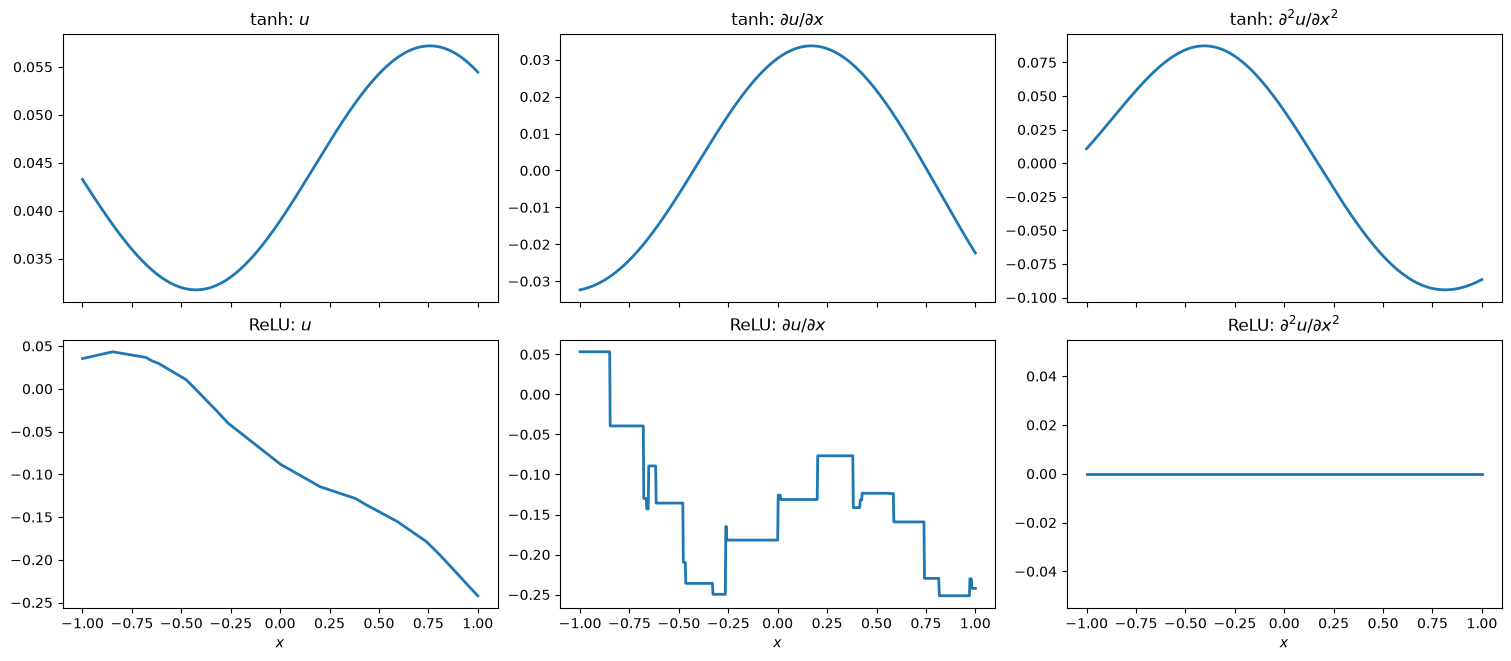

In [2]:
def D(f, v):
    # derivative of f with respect to v at every point; the result stays differentiable
    return torch.autograd.grad(f, v, torch.ones_like(f), create_graph=True)[0]

def small_net(act):
    torch.manual_seed(1)
    return nn.Sequential(nn.Linear(1, 32), act, nn.Linear(32, 32), act, nn.Linear(32, 1))

x = torch.linspace(-1, 1, 801).reshape(-1, 1).requires_grad_(True)
fig, ax = plt.subplots(2, 3, figsize=(15, 6.5), sharex=True, layout="constrained")
for row, (name, act) in enumerate([("tanh", nn.Tanh()), ("ReLU", nn.ReLU())]):
    net = small_net(act)
    u = net(x); ux = D(u, x); uxx = D(ux, x)
    for col, (v, lab) in enumerate(zip([u, ux, uxx], ["$u$", r"$\partial u/\partial x$", r"$\partial^2 u/\partial x^2$"])):
        ax[row, col].plot(x.detach(), v.detach(), lw=2)
        ax[row, col].set_title(f"{name}: {lab}")
    # check autograd against a central finite difference
    h = 1e-4
    with torch.no_grad():
        fd = (net(x + h) - net(x - h)) / (2 * h)
    print(f"{name}: max |autograd du/dx - central difference| = {(ux - fd).abs().max().item():.1e}")
for a in ax[1]: a.set_xlabel("$x$")
plt.show()

**What to observe**

* With tanh, $u$, $\partial u/\partial x$ and $\partial^2 u/\partial x^2$ are all smooth functions.
* With ReLU, $u$ is piecewise linear, $\partial u/\partial x$ is piecewise constant, and $\partial^2 u/\partial x^2$ is exactly zero at every point.
* For tanh, autograd agrees with a central difference to about $10^{-10}$, the error of the finite difference. For ReLU they differ by about $10^{-2}$: near a kink the central difference averages two slopes, while autograd returns one of them.

---
## Part 2: Heat equation

$$\frac{\partial u}{\partial t} = \alpha\,\frac{\partial^2 u}{\partial x^2},\quad x \in [0, 1],\ t \in [0, 1],\quad u(0, t) = u(1, t) = 0,\quad u(x, 0) = \sin(\pi x) + \tfrac12 \sin(3\pi x),$$

with $\alpha = 0.05$. Each sine mode decays at its own rate (Lecture 3), so the exact solution is

$$u(x, t) = e^{-\alpha\pi^2 t}\sin(\pi x) + \tfrac12 e^{-9\alpha\pi^2 t}\sin(3\pi x).$$

**PINN setup.** 4 hidden layers of 32 neurons, inputs scaled to $[-1, 1]$. 2000 random collocation points, 256 initial-condition points, 256 boundary points per side. Loss: mean squared residual + initial-condition error + boundary error, all with weight 1. Adam (learning rate $10^{-3}$ decaying to $10^{-4}$) for 4000 iterations, then L-BFGS. The ReLU model has the same setup with ReLU activations and Adam only.

In [3]:
ALPHA, NU = 0.05, 0.01 / np.pi

class PINN(nn.Module):
    # MLP u_theta(x, t); inputs are scaled to [-1, 1] using the domain
    def __init__(self, width, depth, act, xdom, tdom):
        super().__init__()
        layers = [nn.Linear(2, width)] + [nn.Linear(width, width) for _ in range(depth - 1)]
        self.hidden = nn.ModuleList(layers); self.out = nn.Linear(width, 1)
        self.act = torch.tanh if act == "tanh" else torch.relu
        self.xdom, self.tdom = xdom, tdom
    def forward(self, x, t):
        (x0, x1), (t0, t1) = self.xdom, self.tdom
        h = torch.cat([2 * (x - x0) / (x1 - x0) - 1, 2 * (t - t0) / (t1 - t0) - 1], 1)
        for l in self.hidden: h = self.act(l(h))
        return self.out(h)

def load(name):
    ck = torch.load(os.path.join(DATA_DIR, name + ".pt"), weights_only=False)
    c = ck["cfg"]
    m = PINN(c["width"], c["depth"], c["act"], c["x"], c["t"]); m.load_state_dict(ck["state_dict"]); m.eval()
    return m, c, ck["nu"]

def on_grid(model, nx=256, nt=101):
    (x0, x1), (t0, t1) = model.xdom, model.tdom
    xg, tg = np.linspace(x0, x1, nx), np.linspace(t0, t1, nt)
    X, T = np.meshgrid(xg, tg)                       # rows: time, columns: space
    with torch.no_grad():
        u = model(torch.tensor(X.reshape(-1, 1)), torch.tensor(T.reshape(-1, 1))).numpy().reshape(nt, nx)
    return xg, tg, X, T, u

def rel_l2(a, b): return np.linalg.norm(a - b) / np.linalg.norm(b)

def heat_exact(x, t, a=ALPHA):
    return np.exp(-a * np.pi**2 * t) * np.sin(np.pi * x) + 0.5 * np.exp(-9 * a * np.pi**2 * t) * np.sin(3 * np.pi * x)

H = np.load(os.path.join(DATA_DIR, "histories.npz"), allow_pickle=True)
hist = {k: H[k].item() for k in H.files if H[k].dtype == object}   # loss terms per iteration for each run

def show_maps(xg, tg, u, ref, title):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), layout="constrained")
    ext = [tg[0], tg[-1], xg[0], xg[-1]]
    v = np.abs(ref).max()
    for a, f, ttl in zip(ax[:2], [u, ref], [f"{title}: PINN", "exact"]):
        im = a.imshow(f.T, origin="lower", extent=ext, aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v)
        a.set(xlabel="$t$", ylabel="$x$", title=ttl); fig.colorbar(im, ax=a)
    im = ax[2].imshow(np.abs(u - ref).T, origin="lower", extent=ext, aspect="auto", cmap="magma")
    ax[2].set(xlabel="$t$", ylabel="$x$", title="|PINN - exact|"); fig.colorbar(im, ax=ax[2])
    plt.show()

def show_slices(xg, tg, models, ref, times):
    fig, ax = plt.subplots(1, len(times), figsize=(5 * len(times), 3.8), layout="constrained")
    for a, t in zip(ax, times):
        i = int(round((t - tg[0]) / (tg[-1] - tg[0]) * (len(tg) - 1)))
        a.plot(xg, ref[i], color="0.55", lw=4, label="exact")
        for name, u in models.items(): a.plot(xg, u[i], lw=2, label=name)
        a.set(title=f"t = {t}", xlabel="$x$")
    ax[0].set_ylabel("$u$"); ax[0].legend(); plt.show()

def show_losses(h, title):
    fig, a = plt.subplots(figsize=(8, 4))
    for k in [k for k in h if k not in ("it", "nu", "adam")]:
        a.semilogy(h["it"], h[k], lw=1, label=k)
    if h["adam"] < h["it"][-1]: a.axvline(h["adam"], color="k", ls="--", lw=1, label="Adam → L-BFGS")
    a.set(xlabel="iteration", ylabel="loss", title=title); a.legend(); plt.show()

relative L2 error, tanh PINN: 1.5e-04
relative L2 error, ReLU PINN: 5.8e-01


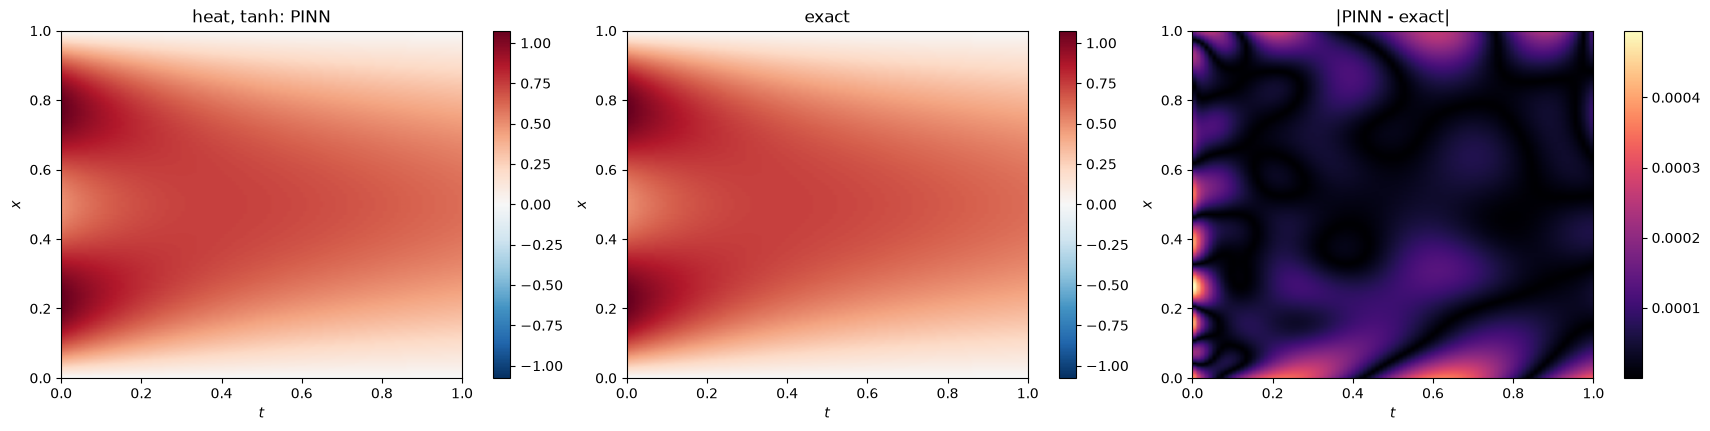

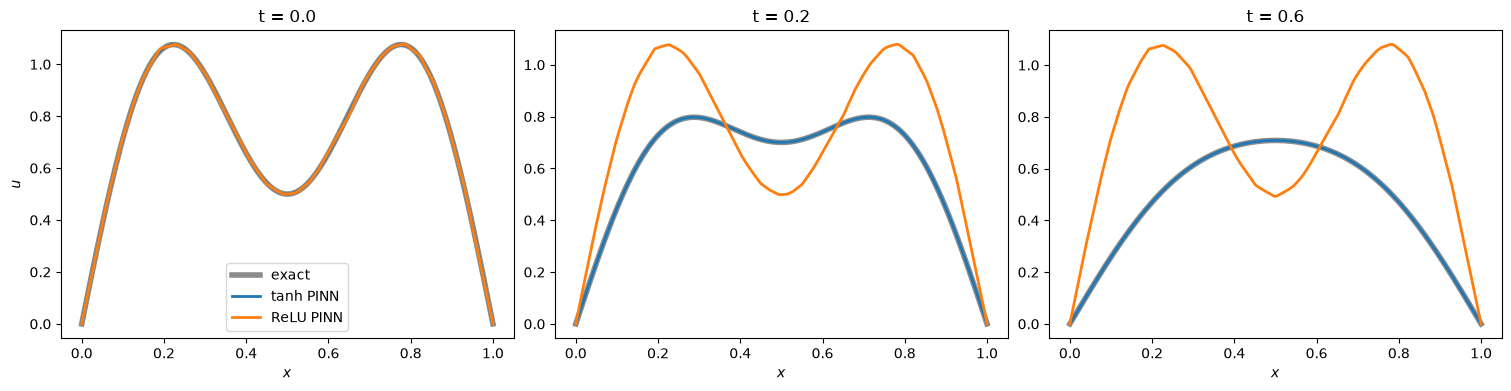

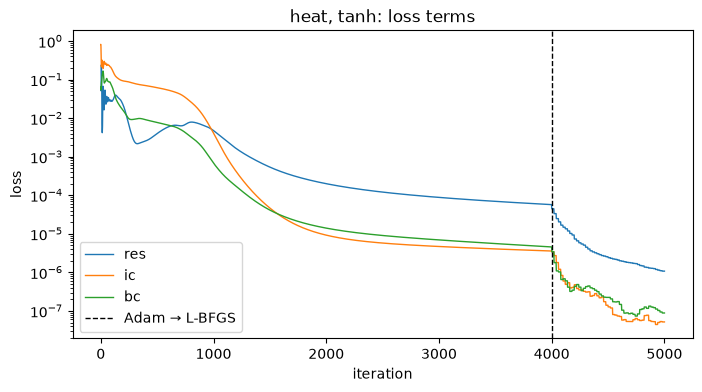

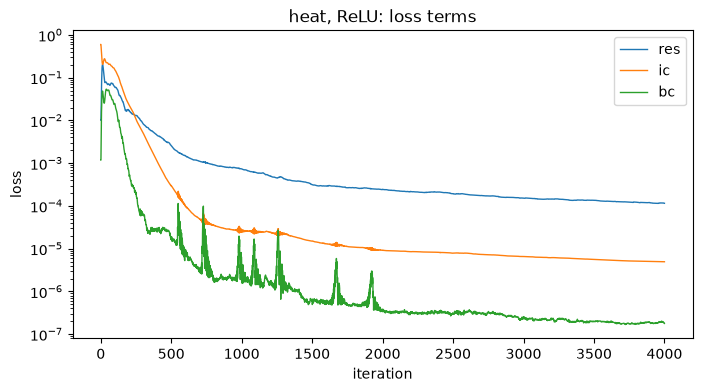

In [4]:
heat, _, _ = load("heat"); heat_relu, _, _ = load("heat_relu")
xg, tg, X, T, u_heat = on_grid(heat); _, _, _, _, u_relu = on_grid(heat_relu)
ref = heat_exact(X, T)
print(f"relative L2 error, tanh PINN: {rel_l2(u_heat, ref):.1e}")
print(f"relative L2 error, ReLU PINN: {rel_l2(u_relu, ref):.1e}")
show_maps(xg, tg, u_heat, ref, "heat, tanh")
show_slices(xg, tg, {"tanh PINN": u_heat, "ReLU PINN": u_relu}, ref, [0.0, 0.2, 0.6])
show_losses(hist["heat"], "heat, tanh: loss terms")
show_losses(hist["heat_relu"], "heat, ReLU: loss terms")

**What to observe**

* The tanh PINN matches the exact solution with relative error of order $10^{-4}$. The $\sin(3\pi x)$ mode decays faster, so the two bumps merge into one by $t \approx 0.6$.
* The ReLU PINN fits the initial condition and then keeps it **unchanged in time**. With $\partial^2 u/\partial x^2 = 0$ the residual reduces to $\partial u/\partial t$, so the network learns $\partial u/\partial t = 0$. Its error is about 60%.
* All three ReLU loss terms are small (residual about $10^{-4}$). A small loss does not mean the network solves the PDE.
* For the tanh PINN, the loss terms drop by one to two orders of magnitude after the switch from Adam to L-BFGS.

---
## Part 3: Burgers' equation

$$\frac{\partial u}{\partial t} + u\,\frac{\partial u}{\partial x} = \nu\,\frac{\partial^2 u}{\partial x^2},\quad x \in [-1, 1],\ t \in [0, 1],\quad u(x, 0) = -\sin(\pi x),\quad u(\pm 1, t) = 0,\quad \nu = 0.01/\pi.$$

**Reference.** The Cole-Hopf transform turns Burgers into the heat equation, which gives

$$u(x, t) = -\frac{\int \sin\big(\pi(x - \eta)\big)\, f(x - \eta)\, e^{-\eta^2/4\nu t}\, d\eta}{\int f(x - \eta)\, e^{-\eta^2/4\nu t}\, d\eta}, \qquad f(y) = e^{-\cos(\pi y)/2\pi\nu}.$$

We evaluate the integrals by quadrature in $\eta$. The exponents are large, so we subtract the largest one before exponentiating.

**PINN setup.** 8 hidden layers of 20 tanh neurons (as in Raissi et al., 2019). 4000 random collocation points, 256 initial-condition points, 256 boundary points per side. Adam for 10000 iterations, then L-BFGS (up to 5000 iterations).

relative L2 error: 2.7e-03


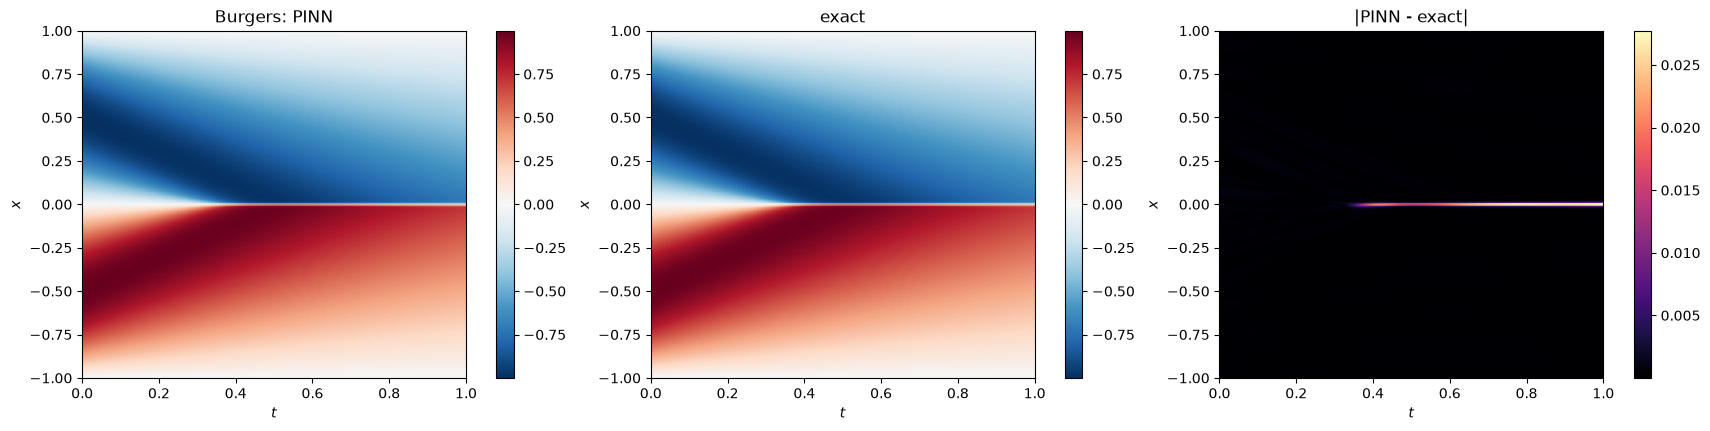

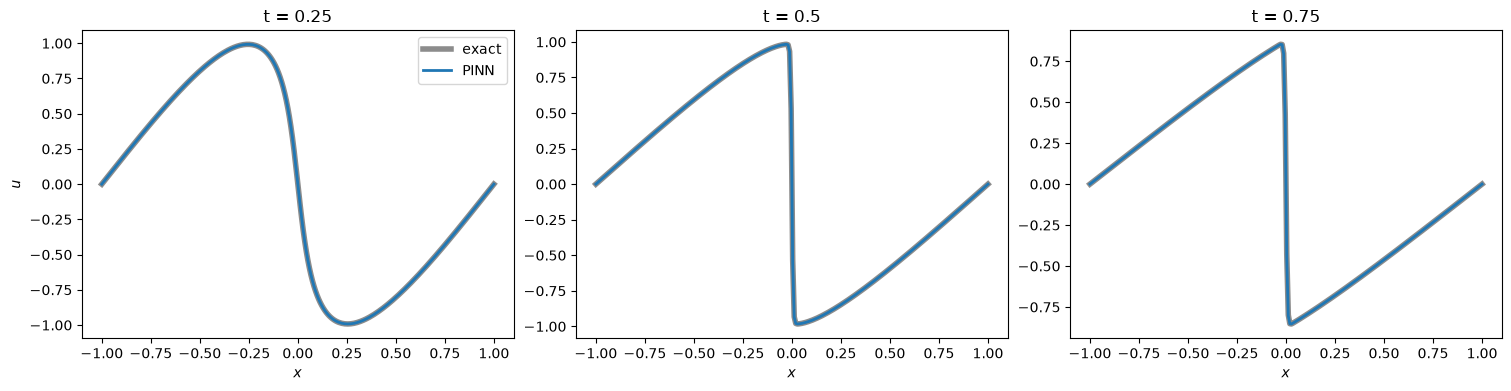

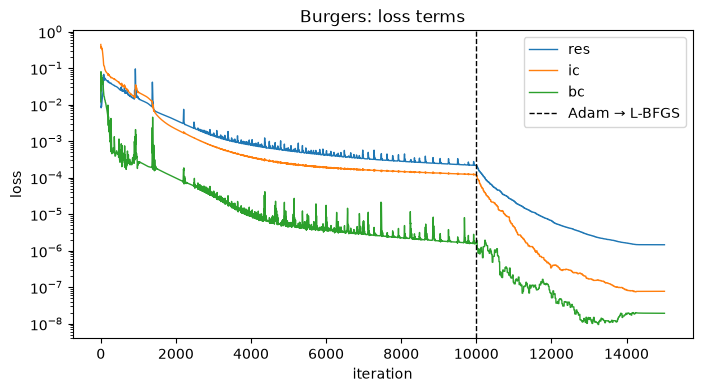

In [5]:
def burgers_exact(x, t, nu=NU, nz=4001):
    x, t = np.broadcast_arrays(np.asarray(x, float), np.asarray(t, float))
    z = np.linspace(-12, 12, nz)                              # eta = sqrt(4 nu t) z
    out = np.empty(x.shape)
    for idx in np.ndindex(x.shape):
        if t[idx] == 0: out[idx] = -np.sin(np.pi * x[idx]); continue
        y = x[idx] - np.sqrt(4 * nu * t[idx]) * z
        logw = -np.cos(np.pi * y) / (2 * np.pi * nu) - z**2
        w = np.exp(logw - logw.max())
        out[idx] = (-np.sin(np.pi * y) * w).sum() / w.sum()
    return out

burgers, _, _ = load("burgers")
xg, tg, X, T, u_b = on_grid(burgers)
ref_b = burgers_exact(X, T)
print(f"relative L2 error: {rel_l2(u_b, ref_b):.1e}")
show_maps(xg, tg, u_b, ref_b, "Burgers")
show_slices(xg, tg, {"PINN": u_b}, ref_b, [0.25, 0.5, 0.75])
show_losses(hist["burgers"], "Burgers: loss terms")

The residual $r_\theta = \partial_t u_\theta + u_\theta\,\partial_x u_\theta - \nu\,\partial_{xx} u_\theta$ of the trained network, on a grid of points that were not used in training:

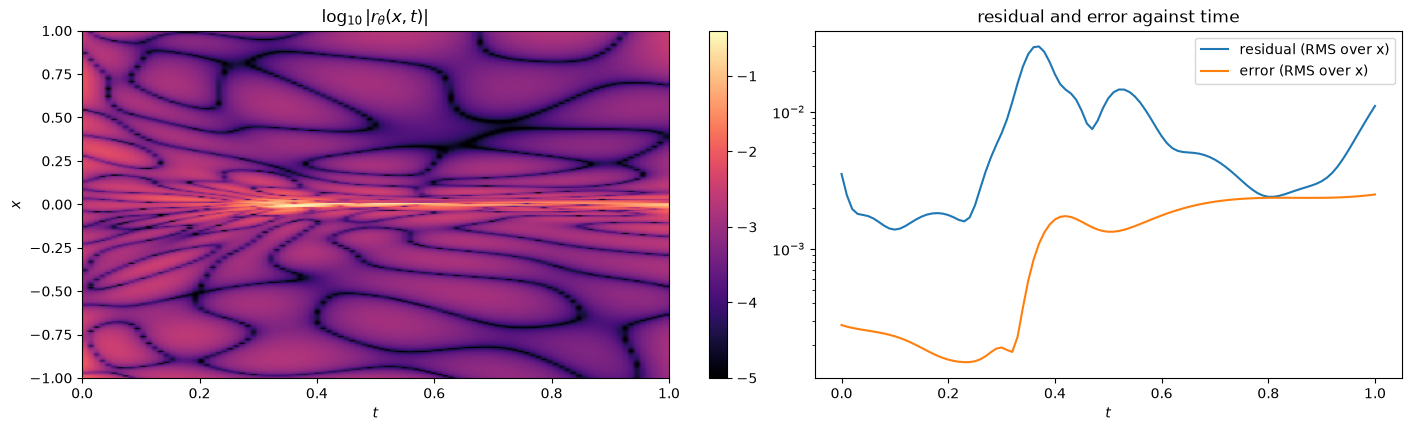

In [6]:
def burgers_residual(model, X, T, nu=NU):
    x = torch.tensor(X.reshape(-1, 1)).requires_grad_(True)
    t = torch.tensor(T.reshape(-1, 1)).requires_grad_(True)
    u = model(x, t); ut, ux = D(u, t), D(u, x); uxx = D(ux, x)
    return (ut + u * ux - nu * uxx).detach().numpy().reshape(X.shape)

r = burgers_residual(burgers, X, T)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), layout="constrained")
im = ax[0].imshow(np.log10(np.abs(r) + 1e-12).T, origin="lower", extent=[0, 1, -1, 1], aspect="auto", cmap="magma", vmin=-5)
ax[0].set(xlabel="$t$", ylabel="$x$", title=r"$\log_{10}|r_\theta(x,t)|$"); fig.colorbar(im, ax=ax[0])
ax[1].semilogy(tg, np.sqrt((r**2).mean(1)), label="residual (RMS over x)")
ax[1].semilogy(tg, np.sqrt(((u_b - ref_b)**2).mean(1)), label="error (RMS over x)")
ax[1].set(xlabel="$t$", title="residual and error against time"); ax[1].legend()
plt.show()

**What to observe**

* The relative error is on the order of $10^{-3}$. The PINN captures the shock at $x = 0$.
* The error is concentrated on the shock, for $t \gtrsim 0.35$. Away from the shock it is below $10^{-3}$.
* The residual is largest on the shock, where $\partial u/\partial x$ is large, and peaks near $t \approx 0.35$, when the shock forms.
* The error jumps by about an order of magnitude when the shock forms and stays at that level afterwards.
* Adam reduces all three loss terms steadily but slowly. After the switch to L-BFGS they fall by about two orders of magnitude.

---
## Part 4: Convection with a large speed

$$\frac{\partial u}{\partial t} + \beta\,\frac{\partial u}{\partial x} = 0,\quad x \in [0, 2\pi]\ \text{periodic},\ t \in [0, 1],\quad u(x, 0) = \sin x,$$

with exact solution $u = \sin(x - \beta t)$, a wave moving to the right at speed $\beta$. Krishnapriyan et al. (NeurIPS 2021) trained PINNs with L-BFGS from a random initialization and found that they fail for $\beta \gtrsim 10$. Rathore et al. (ICML 2024) found that Adam followed by L-BFGS reaches lower loss than either alone.

**PINN setup.** 4 hidden layers of 50 tanh neurons, 4000 collocation points, initial-condition loss, and a periodic boundary loss $\big(u_\theta(0, t) - u_\theta(2\pi, t)\big)^2$. Adam for 4000 iterations, then L-BFGS for up to 2000 iterations. Four checkpoints, same seed:

| checkpoint | $\beta$ | optimizer |
|---|---|---|
| `conv1` | 1 | Adam, then L-BFGS |
| `conv30_adam` | 30 | Adam only (the first phase of `conv30`) |
| `conv30` | 30 | Adam, then L-BFGS |
| `conv50` | 50 | Adam, then L-BFGS |

conv1        beta =    1: relative L2 error 5.6e-04
conv30_adam  beta =   30: relative L2 error 8.2e-01
conv30       beta =   30: relative L2 error 3.7e-02
conv50       beta =   50: relative L2 error 7.6e-01


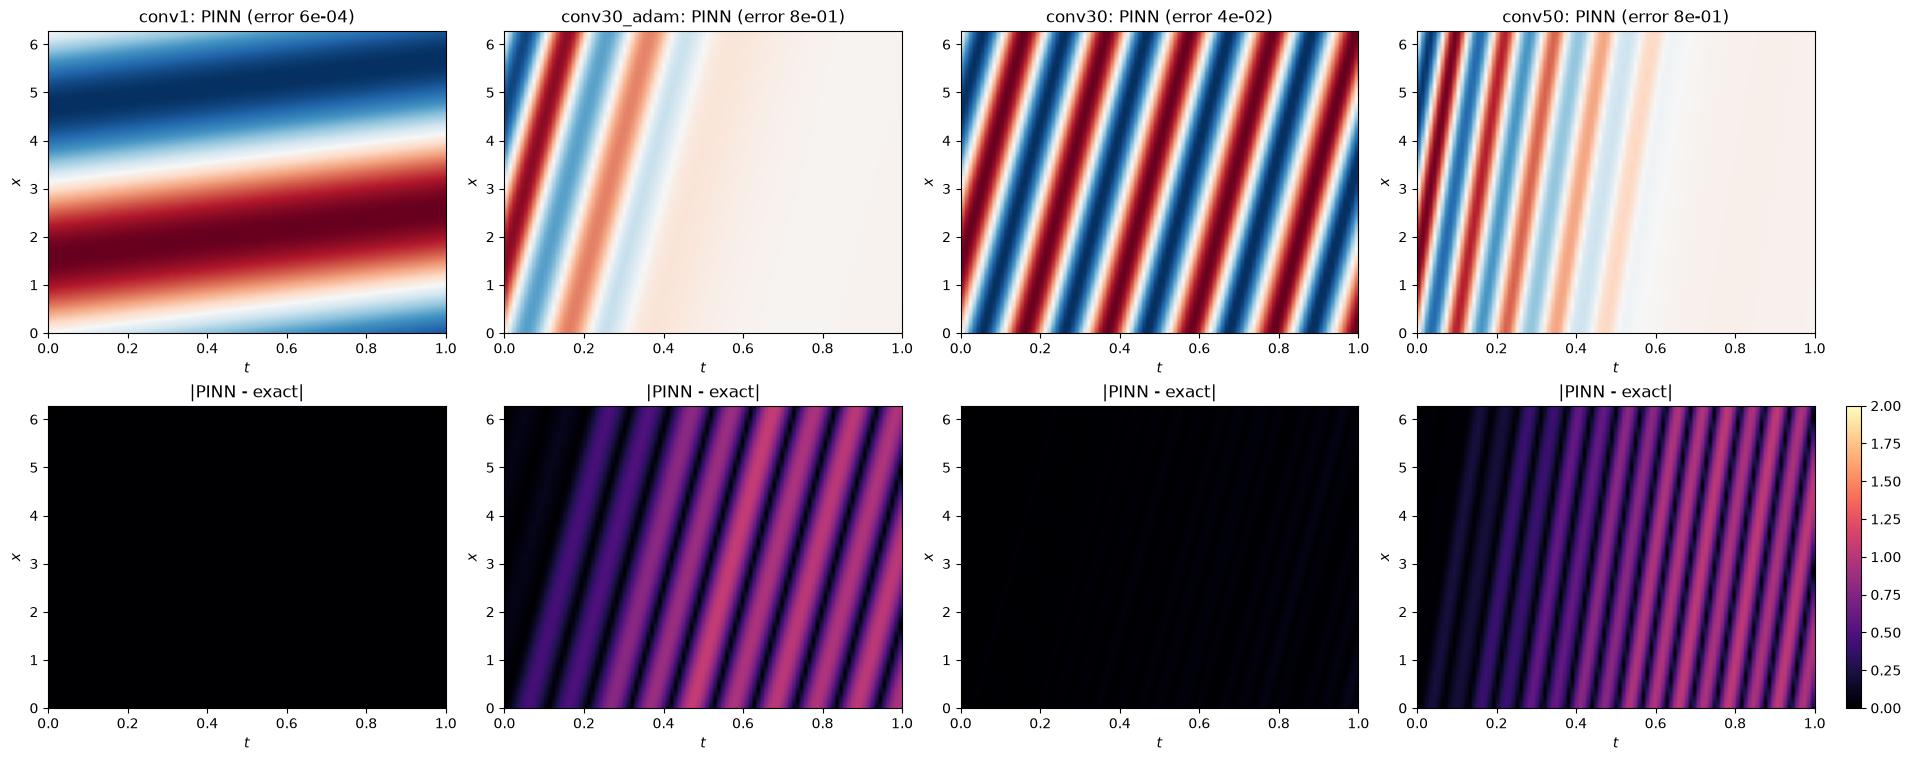

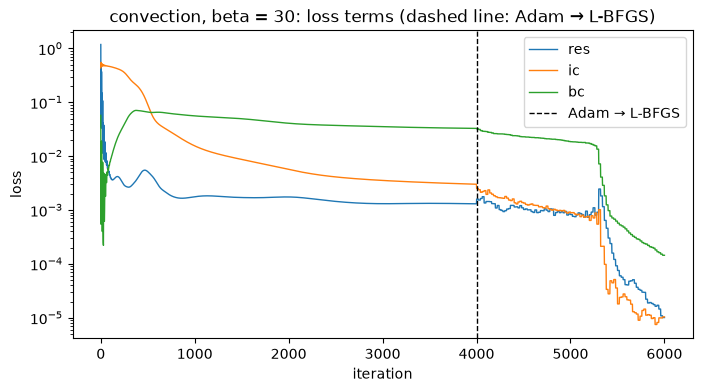

In [7]:
runs = [("conv1", 1.0), ("conv30_adam", 30.0), ("conv30", 30.0), ("conv50", 50.0)]
fig, ax = plt.subplots(2, 4, figsize=(19, 7.5), layout="constrained")
for j, (name, beta) in enumerate(runs):
    m, _, _ = load(name)
    xg, tg, X, T, u = on_grid(m)
    ref_c = np.sin(X - beta * T)
    err = rel_l2(u, ref_c)
    print(f"{name:12s} beta = {beta:4.0f}: relative L2 error {err:.1e}")
    for i, (f, ttl) in enumerate([(u, f"{name}: PINN (error {err:.0e})"), (np.abs(u - ref_c), "|PINN - exact|")]):
        im = ax[i, j].imshow(f.T, origin="lower", extent=[0, 1, 0, 2 * np.pi], aspect="auto",
                             cmap="RdBu_r" if i == 0 else "magma", vmin=-1 if i == 0 else 0, vmax=1 if i == 0 else 2)
        ax[i, j].set(xlabel="$t$", ylabel="$x$", title=ttl)
fig.colorbar(im, ax=ax[1, -1]); plt.show()
show_losses(hist["conv30"], "convection, beta = 30: loss terms (dashed line: Adam → L-BFGS)")

**What to observe**

* $\beta = 1$: the PINN matches the traveling wave, with error of order $10^{-4}$.
* $\beta = 30$, Adam only: the PINN follows the wave for $t \lesssim 0.3$ and then decays to almost zero. Error about 80%, as in Krishnapriyan et al.
* $\beta = 30$, Adam then L-BFGS: error of a few percent, with the same network and collocation points. The loss drops by two orders of magnitude after about 1000 L-BFGS iterations.
* $\beta = 50$: Adam then L-BFGS also fails, in the same way. A better optimizer raises the speed at which training fails but it does not remove the failure.
* In the failed runs the solution decays toward $u = 0$, which satisfies the PDE and the periodic boundary condition and violates only the initial condition.

---
## Part 5: Inverse problem: recover the viscosity

Now $\nu$ is unknown. We have $N_d = 500$ measurements $u_i$ of the Burgers solution at random $(x_i, t_i)$, with Gaussian noise of 1% of the standard deviation of $u$, and no initial or boundary data. The loss is

$$\mathcal L(\theta, \nu) = \frac{1}{N_d}\sum_{i=1}^{N_d}\big(u_\theta(x_i, t_i) - u_i\big)^2 + \frac{1}{N_r}\sum_{j=1}^{N_r} r_{\theta,\nu}(x_j, t_j)^2,$$

and $\log\nu$ is trained together with $\theta$ (the log keeps $\nu$ positive). The estimate starts at $\nu = 0.05$, about 16 times the true value. Same network and optimizer as Part 3.

true nu      = 0.00318
estimated nu = 0.00319  (0.1% error)
relative L2 error of the field: 2.0e-03


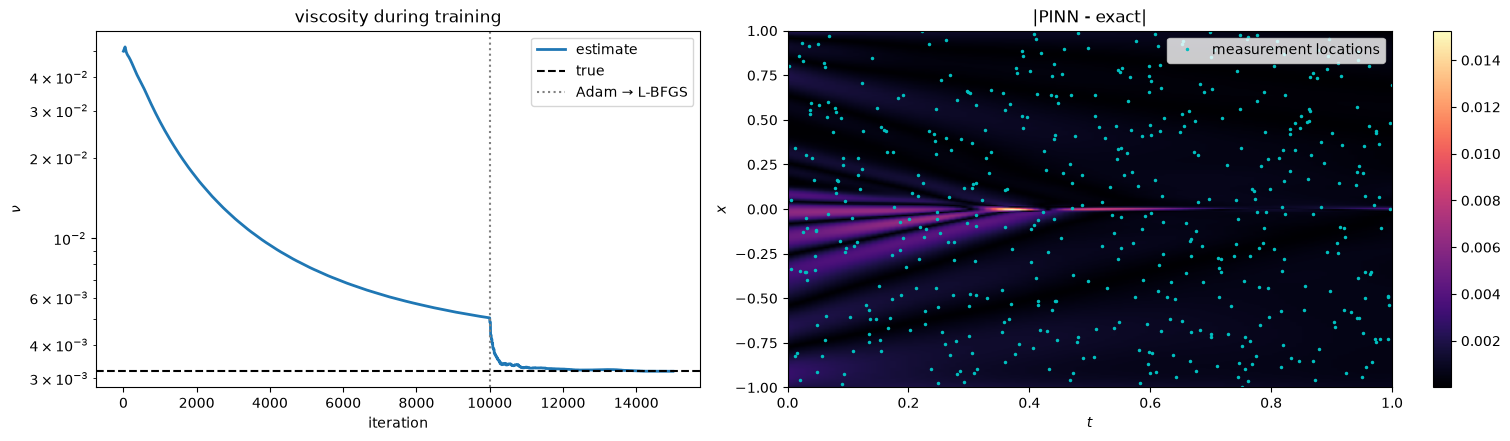

In [8]:
inv, _, nu_hat = load("burgers_inv")
h = hist["burgers_inv"]
print(f"true nu      = {NU:.5f}")
print(f"estimated nu = {nu_hat:.5f}  ({100 * abs(nu_hat - NU) / NU:.1f}% error)")
xg, tg, X, T, u_inv = on_grid(inv)
print(f"relative L2 error of the field: {rel_l2(u_inv, ref_b):.1e}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.3), layout="constrained")
ax[0].semilogy(h["it"], h["nu"], lw=2, label="estimate"); ax[0].axhline(NU, color="k", ls="--", label="true")
ax[0].axvline(h["adam"], color="0.5", ls=":", label="Adam → L-BFGS")
ax[0].set(xlabel="iteration", ylabel=r"$\nu$", title="viscosity during training"); ax[0].legend()
im = ax[1].imshow(np.abs(u_inv - ref_b).T, origin="lower", extent=[0, 1, -1, 1], aspect="auto", cmap="magma")
ax[1].plot(H["inv_td"], H["inv_xd"], ".", color="c", ms=3, label="measurement locations")
ax[1].set(xlabel="$t$", ylabel="$x$", title="|PINN - exact|"); ax[1].legend(loc="upper right"); fig.colorbar(im, ax=ax[1])
plt.show()

**What to observe**

* $\nu$ falls slowly during Adam and is still about 60% too large at the switch to L-BFGS. L-BFGS brings it to the true value within a few hundred iterations. The final error is about 0.1%.
* The field error is about $2\times10^{-3}$, similar to the forward PINN in Part 3, which knew $\nu$ and had the initial and boundary conditions.
* The error is largest near $x = 0$ before and while the shock forms ($t \lesssim 0.4$).
* 500 measurements cover the domain sparsely and the residual fills in the field between them.

---
## Exercises

1. **Number of collocation points.** Train the heat PINN with $N_r$ = 20, 100, 500 and 2000 collocation points (`train_pinn("heat", nf=...)`). Plot the test error on the grid and the final residual loss against $N_r$. Where does the network satisfy the PDE at the training points but not between them?
2. **Curriculum.** Train the convection PINN for $\beta$ = 5, 10, 15, ..., 30, starting each stage from the previous weights (`init=`). Compare the final error at $\beta = 30$ with `conv30`. Then try time marching: train on $t \in [0, 0.1]$, use the prediction at $t = 0.1$ as the initial condition for $[0.1, 0.2]$, and so on.
3. **Loss weights.** Retrain Burgers with weight 10 and 100 on the initial-condition loss. Then implement the learning-rate annealing of Wang, Teng & Perdikaris (2021): every 100 iterations, set $\hat\lambda = \max|\nabla_\theta \mathcal L_r| / \overline{|\nabla_\theta (\lambda\mathcal L_0)|}$ and $\lambda \leftarrow 0.9\lambda + 0.1\hat\lambda$. Which converges fastest?
4. **Causal weights.** Add the causal weights of Wang, Sankaran & Perdikaris (2024) to the Burgers loss: split $[0, 1]$ into 32 time slices, compute the mean residual on each, and weight slice $i$ by $\exp(-\epsilon\sum_{k<i}\mathcal L_r(t_k))$ with $\epsilon = 1$ (no gradient through the weights). Plot the error against time at a few points during training and compare with Part 3.

In [9]:
# Training code (used for the checkpoints; run offline, e.g. on one HPC3 GPU)
def train_pinn(problem, nf=None, adam=None, lbfgs=None, init=None, seed=0, beta=None, ndata=500, noise=0.01, nu0=0.05):
    cfg = {
        "heat":        dict(x=(0, 1), t=(0, 1), width=32, depth=4, nf=2000, adam=4000, lbfgs=1000, act="tanh"),
        "heat_relu":   dict(x=(0, 1), t=(0, 1), width=32, depth=4, nf=2000, adam=4000, lbfgs=0, act="relu"),
        "burgers":     dict(x=(-1, 1), t=(0, 1), width=20, depth=8, nf=4000, adam=10000, lbfgs=5000, act="tanh"),
        "burgers_inv": dict(x=(-1, 1), t=(0, 1), width=20, depth=8, nf=4000, adam=10000, lbfgs=5000, act="tanh"),
        "conv":        dict(x=(0, 2 * np.pi), t=(0, 1), width=50, depth=4, nf=4000, adam=4000, lbfgs=2000, act="tanh"),
    }[problem]
    for k, v in dict(nf=nf, adam=adam, lbfgs=lbfgs).items():
        if v is not None: cfg[k] = v
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    (x0, x1), (t0, t1) = cfg["x"], cfg["t"]
    net = PINN(cfg["width"], cfg["depth"], cfg["act"], cfg["x"], cfg["t"])
    for l in list(net.hidden) + [net.out]: nn.init.xavier_normal_(l.weight); nn.init.zeros_(l.bias)
    if init is not None: net.load_state_dict(init.state_dict())
    params = list(net.parameters())
    log_nu = None
    if problem == "burgers_inv":
        log_nu = nn.Parameter(torch.tensor(np.log(nu0))); params.append(log_nu)
    col = lambda a: torch.tensor(np.asarray(a, float)).reshape(-1, 1)
    xf = col(rng.uniform(x0, x1, cfg["nf"])).requires_grad_(True)     # collocation points
    tf = col(rng.uniform(t0, t1, cfg["nf"])).requires_grad_(True)
    xi = col(np.linspace(x0, x1, 256)); ti = torch.zeros_like(xi)       # initial-condition points
    tb = col(np.linspace(t0, t1, 256))                                  # boundary points
    if problem.startswith("heat"): ui = col(heat_exact(xi.numpy().ravel(), 0))
    elif problem.startswith("burgers"): ui = -torch.sin(np.pi * xi)
    else: ui = torch.sin(xi)
    if problem == "burgers_inv":
        xd, td = rng.uniform(x0, x1, ndata), rng.uniform(t0, t1, ndata)
        ud = burgers_exact(xd, td); ud = ud + noise * ud.std() * rng.standard_normal(ndata)
        xd, td, ud = col(xd), col(td), col(ud)

    def residual():
        u = net(xf, tf); ut, ux = D(u, tf), D(u, xf)
        if problem.startswith("heat"): return ut - ALPHA * D(ux, xf)
        if problem == "burgers": return ut + u * ux - NU * D(ux, xf)
        if problem == "burgers_inv": return ut + u * ux - torch.exp(log_nu) * D(ux, xf)
        return ut + beta * ux

    def losses():
        L = {"res": (residual() ** 2).mean()}
        if problem == "burgers_inv":
            L["data"] = ((net(xd, td) - ud) ** 2).mean(); return L
        L["ic"] = ((net(xi, ti) - ui) ** 2).mean()
        xa, xb = torch.full_like(tb, x0), torch.full_like(tb, x1)
        if problem == "conv": L["bc"] = ((net(xa, tb) - net(xb, tb)) ** 2).mean()     # periodic
        else: L["bc"] = (net(xa, tb) ** 2).mean() + (net(xb, tb) ** 2).mean()           # u = 0 at both ends
        return L

    hist = {"it": [], "adam": cfg["adam"]}
    def record(it, L):
        hist["it"].append(it)
        for k, v in L.items(): hist.setdefault(k, []).append(float(v))
        if log_nu is not None: hist.setdefault("nu", []).append(float(torch.exp(log_nu)))

    opt = torch.optim.Adam(params, lr=1e-3)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.1 ** (1 / max(cfg["adam"], 1)))   # 1e-3 -> 1e-4
    for it in range(cfg["adam"]):
        opt.zero_grad(); L = losses(); sum(L.values()).backward(); opt.step(); sched.step()
        record(it, L)
    if cfg["lbfgs"]:
        # max_iter > 1 per call: with max_iter=1, torch's L-BFGS makes no progress between calls
        lb = torch.optim.LBFGS(params, lr=1.0, max_iter=20, history_size=50, line_search_fn="strong_wolfe",
                               tolerance_grad=1e-12, tolerance_change=1e-14)
        def closure():
            lb.zero_grad(); loss = sum(losses().values()); loss.backward(); return loss
        it, prev = cfg["adam"], None
        while it < cfg["adam"] + cfg["lbfgs"]:
            n0 = lb.state[lb._params[0]].get("n_iter", 0); lb.step(closure); n1 = lb.state[lb._params[0]].get("n_iter", 0)
            L = {a: b.detach() for a, b in losses().items()}; tot = float(sum(L.values()))
            if n1 == n0 or (prev is not None and abs(prev - tot) < 1e-13 * max(1, tot)): break   # converged
            it += n1 - n0; record(it, L); prev = tot
    return net, hist, (float(torch.exp(log_nu)) if log_nu is not None else None)

# Example (about 1 minute on a CPU):
# net, h, _ = train_pinn("heat")
# net, h, _ = train_pinn("conv", beta=30.0)